In [ ]:
# import
import matplotlib.pyplot as plt
from scipy.io import wavfile
%run ./init.py

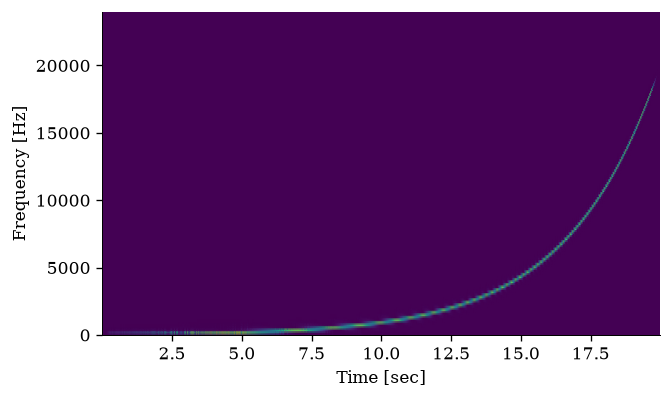

In [85]:
# load audio file
x, fs = wavread('assets/sweep_ref.wav')

# spectrogram
f, t, Sxx = scipy.signal.spectrogram(x, fs)

plt.pcolormesh(t, f, Sxx, shading='gouraud')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
# plt.ylim([20, 10000])
plt.show()

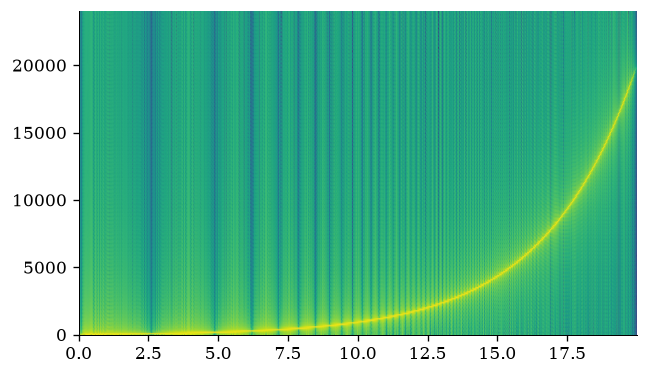

In [90]:
# load audio file
x, fs = wavread('assets/sweep_ref.wav')
# x, fs = wavread('assets/drums.wav')

# init locals
block_duration_in_sec = 0.01
n_sample_per_block = math.ceil(block_duration_in_sec * fs)
n_blocks = math.floor( len(x) / n_sample_per_block )
S = np.zeros([n_blocks, round(n_sample_per_block/2)+1])

# loop over blocks
for i_block in range(n_blocks):

    # extract audio
    selvect = np.arange(n_sample_per_block) + i_block * n_sample_per_block
    
    # fft
    X = np.fft.rfft(x[selvect], n_sample_per_block)
    X = 20*np.log(np.abs(X))

    # save to locals
    S[i_block, :] = X

# plot
t = n_sample_per_block * np.arange(n_blocks) / fs
f = np.fft.rfftfreq(n_sample_per_block, 1/fs)
plt.pcolormesh(t, f, np.transpose(S), shading="gouraud")
# plt.yscale('log')
plt.show()